In [1]:
#!/usr/bin/env python3

import re
import json
import ast
import numpy as np
import pandas as pd
import networkx as nx

from scipy.stats import fisher_exact
from scipy.stats import hypergeom

##############################################################################
# PARAMETERS
##############################################################################

N_PERMUTATIONS = 10000

HPO_FILE = "/Volumes/mac1/data/limb/HPO.csv"
FIMO_FILE = "/Volumes/mac1/data/limb/fimo_all/fimo.tsv"
NETWORK_FILE = "/Volumes/mac1/data/limb/reseau.html"

##############################################################################
# LOAD NETWORK FROM HTML
##############################################################################

print("Loading network...")

html = open(NETWORK_FILE, encoding="utf-8").read()

nodes_match = re.search(
    r'nodes\s*=\s*new vis\.DataSet\((\[.*?\])\s*\)\s*;',
    html,
    re.S
)

edges_match = re.search(
    r'edges\s*=\s*new vis\.DataSet\((\[.*?\])\s*\)\s*;',
    html,
    re.S
)

if nodes_match is None:
    raise ValueError("Nodes not found")

nodes_text = nodes_match.group(1)
nodes = json.loads(nodes_text)

print(f"{len(nodes)} nodes loaded")

if edges_match:
    try:
        edges = json.loads(edges_match.group(1))
    except:
        edges = []
else:
    edges = []

##############################################################################
# BUILD GRAPH
##############################################################################

G = nx.Graph()

for n in nodes:
    G.add_node(n["id"])

for e in edges:

    source = e.get("from")
    target = e.get("to")

    if source and target:
        G.add_edge(source, target)

##############################################################################
# NETWORK METRICS
##############################################################################

print("Calculating network metrics")

metrics = {}

metrics["nodes"] = G.number_of_nodes()
metrics["edges"] = G.number_of_edges()
metrics["density"] = nx.density(G)

degrees = dict(G.degree())

metrics["mean_degree"] = np.mean(list(degrees.values()))
metrics["max_degree"] = np.max(list(degrees.values()))

metrics["connected_components"] = nx.number_connected_components(G)

if nx.number_of_nodes(G) > 1:

    largest_cc = max(nx.connected_components(G), key=len)

    SG = G.subgraph(largest_cc)

    metrics["clustering"] = nx.average_clustering(SG)

    try:
        metrics["diameter"] = nx.diameter(SG)
    except:
        metrics["diameter"] = np.nan

    try:
        metrics["average_path_length"] = nx.average_shortest_path_length(SG)
    except:
        metrics["average_path_length"] = np.nan

##############################################################################
# CENTRALITIES
##############################################################################

print("Centralities")

deg_cent = nx.degree_centrality(G)
betw_cent = nx.betweenness_centrality(G)
close_cent = nx.closeness_centrality(G)

try:
    eig_cent = nx.eigenvector_centrality(G, max_iter=500)
except:
    eig_cent = {k: np.nan for k in G.nodes()}

centrality_df = pd.DataFrame({
    "TF": list(G.nodes()),
    "degree": [degrees[x] for x in G.nodes()],
    "degree_centrality": [deg_cent[x] for x in G.nodes()],
    "betweenness": [betw_cent[x] for x in G.nodes()],
    "closeness": [close_cent[x] for x in G.nodes()],
    "eigenvector": [eig_cent[x] for x in G.nodes()]
})

centrality_df.sort_values(
    "degree",
    ascending=False
).to_csv(
    "/Volumes/mac1/data/limb/network_centralities.csv",
    index=False
)

##############################################################################
# LOAD FIMO
##############################################################################

print("Loading FIMO")

fimo = pd.read_csv(FIMO_FILE, sep="\t", comment="#")

print(f"{len(fimo)} motif matches")

##############################################################################
# TF ENRICHMENT
##############################################################################

if "motif_id" in fimo.columns:
    tf_column = "motif_id"
elif "motif_alt_id" in fimo.columns:
    tf_column = "motif_alt_id"
else:
    tf_column = fimo.columns[0]

tf_counts = (
    fimo.groupby(tf_column)
    .size()
    .reset_index(name="n_sites")
    .sort_values("n_sites", ascending=False)
)

tf_counts.to_csv(
    "/Volumes/mac1/data/limb/TF_counts.csv",
    index=False
)

##############################################################################
# LOAD HPO
##############################################################################

print("Loading HPO")

hpo = pd.read_csv(HPO_FILE)

gene_col = hpo.columns[0]

hpo_genes = set(
    hpo[gene_col]
    .dropna()
    .astype(str)
)

network_genes = set(G.nodes())

##############################################################################
# HYPERGEOMETRIC TEST
##############################################################################

background_size = 20000

K = len(hpo_genes)

n = len(network_genes)

k = len(
    network_genes.intersection(
        hpo_genes
    )
)

hyper_p = hypergeom.sf(
    k - 1,
    background_size,
    K,
    n
)

##############################################################################
# FISHER TEST
##############################################################################

a = k
b = n - k

c = K - k
d = background_size - (a + b + c)

table = [
    [a, b],
    [c, d]
]

odds_ratio, fisher_p = fisher_exact(
    table,
    alternative="greater"
)

from statsmodels.stats.contingency_tables import Table2x2

table = [[a,b],[c,d]]

ci_low, ci_high = (
    Table2x2(table)
    .oddsratio_confint()
)

##############################################################################
# PERMUTATION TEST
##############################################################################

print("Permutation test")

universe = list(range(background_size))

obs = k

perm = []

for i in range(N_PERMUTATIONS):

    random_set = set(
        np.random.choice(
            universe,
            size=n,
            replace=False
        )
    )

    simulated_hits = np.random.hypergeometric(
        ngood=K,
        nbad=background_size-K,
        nsample=n
    )

    perm.append(simulated_hits)

perm = np.array(perm)

empirical_p = (
    np.sum(perm >= obs) + 1
) / (N_PERMUTATIONS + 1)

zscore = (
    obs - np.mean(perm)
) / np.std(perm)

##############################################################################
# RESULTS TABLE
##############################################################################

metrics_table = pd.DataFrame({

    "Metric":[
        "Nodes",
        "Edges",
        "Density",
        "Mean degree",
        "Max degree",
        "Connected components",
        "Clustering coefficient",
        "Diameter",
        "Average path length",
        "Hypergeometric p",
        "Fisher OR",
        "Fisher p",
        "Observed overlap",
        "Permutation p",
        "Permutation Zscore",
        "Odds ratio CI Low",
        "Odds ratio CI High"
    ],

    "Value":[
        metrics.get("nodes"),
        metrics.get("edges"),
        metrics.get("density"),
        metrics.get("mean_degree"),
        metrics.get("max_degree"),
        metrics.get("connected_components"),
        metrics.get("clustering"),
        metrics.get("diameter"),
        metrics.get("average_path_length"),
        hyper_p,
        odds_ratio,
        fisher_p,
        k,
        empirical_p,
        zscore,
        ci_low,
        ci_high
    ]
})

metrics_table.to_csv(
    "/Volumes/mac1/data/limb/network_statistics.csv",
    index=False
)

##############################################################################
# TOP HUBS
##############################################################################

top_hubs = centrality_df.sort_values(
    "degree",
    ascending=False
).head(20)

top_hubs.to_csv(
    "/Volumes/mac1/data/limb/top20_hubs.csv",
    index=False
)

##############################################################################
# SUMMARY
##############################################################################

print("\n==== RESULTS ====")

print(metrics_table)

print("\nTop hubs")
print(top_hubs.head())

print("\nFiles generated:")
print("/Volumes/mac1/data/limb/network_statistics.csv")
print("/Volumes/mac1/data/limb/network_centralities.csv")
print("/Volumes/mac1/data/limb/TF_counts.csv")
print("/Volumes/mac1/data/limb/top20_hubs.csv")

Loading network...
198 nodes loaded
Calculating network metrics
Centralities
Loading FIMO
391122 motif matches
Loading HPO
Permutation test

==== RESULTS ====
                    Metric        Value
0                    Nodes   198.000000
1                    Edges   267.000000
2                  Density     0.013690
3              Mean degree     2.696970
4               Max degree    54.000000
5     Connected components     1.000000
6   Clustering coefficient     0.000000
7                 Diameter     6.000000
8      Average path length     3.515613
9         Hypergeometric p     1.000000
10               Fisher OR     0.000000
11                Fisher p     1.000000
12        Observed overlap     0.000000
13           Permutation p     1.000000
14      Permutation Zscore    -0.102016
15       Odds ratio CI Low     1.672687
16      Odds ratio CI High  1494.752020

Top hubs
                 TF  degree  degree_centrality  betweenness  closeness  \
45         Skeletal      54          

In [26]:
# 01_extract_vcf.py

import pandas as pd

vcf = pd.read_csv(
    "/Volumes/mac1/data/limb/limb_variants.csv",
    sep=";",
    header=1,
    #comment="#"
)

cols = [
    "#CHROM",
    "POS",
    "REF",
    "ALT",
]

vcf = vcf[cols]

vcf.rename(
    columns={"#CHROM": "chrom"},
    inplace=True
)

vcf.to_csv(
    "/Volumes/mac1/data/limb/results/variants_filtered.csv",
    index=False
)

In [30]:
# 02_hpo_network.py

import pandas as pd
import networkx as nx

edges = pd.read_csv("/Volumes/mac1/data/limb/results/edges.csv")

G = nx.from_pandas_edgelist(
    edges,
    source="source",
    target="target"
)

degree = nx.degree_centrality(G)
betweenness = nx.betweenness_centrality(G)
closeness = nx.closeness_centrality(G)
eigen = nx.eigenvector_centrality(G)

df = pd.DataFrame({
    "node": list(degree.keys()),
    "degree": list(degree.values()),
    "betweenness": [betweenness[n] for n in degree],
    "closeness": [closeness[n] for n in degree],
    "eigenvector": [eigen[n] for n in degree]
})

df.sort_values(
    "degree",
    ascending=False
).to_csv(
    "/Volumes/mac1/data/limb/results/hpo_hubs.csv",
    index=False
)

In [32]:
# 03_fimo_analysis.py

import pandas as pd

fimo = pd.read_csv(
    "/Volumes/mac1/data/limb/fimo_all/fimo.tsv",
    sep="\t"
)

counts = (
    fimo
    .groupby("motif_id")
    .size()
    .reset_index(name="n_sites")
)

counts.sort_values(
    "n_sites",
    ascending=False
).to_csv(
    "/Volumes/mac1/data/limb/results/TF_counts.csv",
    index=False
)

In [37]:
# 04_finngen_analysis.py

import pandas as pd

gwas = pd.read_csv(
    "/Volumes/mac1/data/limb/risteys_codewas_Q17_OTHER_CONGEN_MALFO_LIMBS.csv"
)

gwas["minus_log10_p"] = -np.log10(
    gwas["-log10(p)"]
)

significant = gwas[
    gwas["minus_log10_p"] < 1e-5
]

significant.to_csv(
    "/Volumes/mac1/data/limb/results/finngen_significant.csv",
    index=False
)


In [3]:
all_tested_tfs = set()
with open("/Volumes/mac1/data/limb/motifs_human.txt", "r") as f:
    lines = f.readlines()
    for line in lines:
        if line.startswith("MOTIF"):
            parts = line.split()
            tf_name = parts[1]
            all_tested_tfs.add(tf_name)
len(all_tested_tfs)

5567

In [8]:
corrected_tf = set()
for x in all_tested_tfs:
    try:
        ctf = x.split("_")[0]
        if "." in ctf:
            ctf = ctf.split(".")[0]
        corrected_tf.add(ctf)
    except:
        corrected_tf.add(x)
len(corrected_tf)

2770

In [9]:
corrected_tf

{'V$POU6F1',
 'MA0079',
 'achi',
 'HA-sp',
 'POU2F2',
 'HXD4',
 'SOX4',
 'Phox2a',
 'VAX1',
 'OLIG2',
 'pTH6636',
 'YY2',
 'Dlx5',
 'ZNF784',
 'pTH9310',
 'ZNF749',
 'NEUROD2',
 'pTH7965',
 'ZBTB33',
 'CEBPB',
 'HSF4',
 'MAFG',
 'MA0579',
 'Q86W11',
 'ZNF276',
 'HepG2b',
 'V$CP2',
 'Isl2',
 'SPI1',
 'MA0226',
 'HES5',
 'ESRRA',
 'ZNF26',
 'unpg',
 'DMRTC2',
 'HXB6',
 'pTH6281',
 'HNF6',
 'fd59A',
 'LMX1B',
 'ZNF398',
 'MA0088',
 'ETV1',
 'NFATc1',
 'ZNF549',
 'BHLHE23',
 'V$SREBP1',
 'MA0386',
 'GLIS2',
 'P17039',
 'ALX4',
 'pTH9269',
 'pTH6140',
 'Hmx1',
 'Sp4',
 'ZBTB37',
 'HEK293b',
 'pTH9262',
 'POU6F1',
 'GM12878-PAX5',
 'Ceh-22',
 'TFAP2C',
 'ARNT',
 'STF1',
 'BPTF',
 'POU4F3',
 'AP2B',
 'HEK293',
 'Jurkat-ELF1',
 'BCL6',
 'MA0210',
 'MA0056',
 'FOXD3',
 'HeLa-S3',
 'Q8NBF1',
 'ZSCAN1',
 'V$MEF2',
 'pTH5112',
 'Atf1',
 'CG18619',
 'IRX3',
 'MA0067',
 'Myoblast-Pax7',
 'THRB',
 'HOXB2',
 'Ipf1',
 'Erythrocyte-Klf1',
 'MA0228',
 'pTH4426',
 'Gata5',
 'EGR2',
 'MYOG',
 'VCaP-SPDEF',

In [10]:
import pandas as pd
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import Table2x2
import numpy as np

hpo = pd.read_csv("/Volumes/mac1/data/limb/HPO.csv")
gain = pd.read_csv("/Volumes/mac1/data/limb/gained_all.csv")
loss = pd.read_csv("/Volumes/mac1/data/limb/lost_all.csv")


all_tested_tfs = set()
with open("/Volumes/mac1/data/limb/motifs_human.txt", "r") as f:
    lines = f.readlines()
    for line in lines:
        if line.startswith("MOTIF"):
            parts = line.split()
            tf_name = parts[1]
            all_tested_tfs.add(tf_name)

corrected_tf = set()
for x in all_tested_tfs:
    try:
        ctf = x.split("_")[0]
        if "." in ctf:
            ctf = ctf.split(".")[0]
        corrected_tf.add(ctf)
    except:
        corrected_tf.add(x)

all_tested_tfs = corrected_tf
# =====================================================
# TF perturbés
# =====================================================

gain_tfs = set(
    gain["TF"]
    .dropna()
    .astype(str)
    .str.strip()
)

loss_tfs = set(
    loss["TF"]
    .dropna()
    .astype(str)
    .str.strip()
)

perturbed_tfs = gain_tfs | loss_tfs

print("TF perturbés =", len(perturbed_tfs))
print("TF background =", len(all_tested_tfs))

# =====================================================
# Gènes HPO
# =====================================================

all_hpo_genes = set()

for genes in hpo["Genes"].dropna():

    genes_set = {
        g.strip()
        for g in str(genes).split(";")
        if g.strip()
    }

    all_hpo_genes |= genes_set

# =====================================================
# Contrôle qualité
# =====================================================

detected_hpo_tfs = (
    all_hpo_genes &
    all_tested_tfs
)

print(
    "HPO TF dans background =",
    len(detected_hpo_tfs)
)

# =====================================================
# Enrichissement HPO
# =====================================================

results = []

for _, row in hpo.iterrows():

    term = row["Term"]

    term_tfs = {
        g.strip()
        for g in str(row["Genes"]).split(";")
        if g.strip()
    }

    term_tfs = term_tfs & all_tested_tfs

    if len(term_tfs) == 0:
        continue

    overlap = (
        perturbed_tfs &
        term_tfs
    )

    a = len(overlap)

    b = len(
        perturbed_tfs -
        term_tfs
    )

    c = len(
        term_tfs -
        perturbed_tfs
    )

    d = len(
        all_tested_tfs -
        (
            perturbed_tfs |
            term_tfs
        )
    )

    contingency_table = [
        [a, b],
        [c, d]
    ]

    odds_ratio, p_value = fisher_exact(
        contingency_table,
        alternative="greater"
    )

    table = [[a,b],[c,d]]

    ci_low, ci_high = (
        Table2x2(table)
        .oddsratio_confint()
    )
    results.append(
        {
            "Term": term,
            "HPO_size": len(term_tfs),
            "Overlap": a,
            "OddsRatio": odds_ratio,
            "Pvalue": p_value,
            "CI_Low": ci_low,
            "CI_High": ci_high,
            "Overlap_genes":
                ";".join(sorted(overlap))
        }
    )

# =====================================================
# FDR
# =====================================================

results_df = pd.DataFrame(results)

results_df["FDR"] = multipletests(
    results_df["Pvalue"],
    method="fdr_bh"
)[1]

results_df = results_df.sort_values(
    [
        "FDR",
        "Pvalue",
        "Overlap"
    ],
    ascending=[
        True,
        True,
        False
    ]
)

results_df.to_csv(
    "/Volumes/mac1/data/limb/results/HPO_TF_enrichment_backgroundTF.csv",
    index=False
)

print(
    results_df.head(50)
)

TF perturbés = 253
TF background = 2770
HPO TF dans background = 55
                                                  Term  HPO_size  Overlap  \
0          Autosomal dominant inheritance (HP:0000006)        33       29   
626       Autosomal recessive inheritance (HP:0000007)        22       21   
13                         Cryptorchidism (HP:0000028)        12       11   
43                 Depressed nasal bridge (HP:0005280)         9        8   
82                          Hypertelorism (HP:0000316)         9        8   
32                           Constipation (HP:0002019)         7        7   
21             Radial deviation of finger (HP:0009466)        10        8   
24        Intrauterine growth retardation (HP:0001511)        10        8   
18                       Malar flattening (HP:0000272)         8        7   
65                        Frontal bossing (HP:0002007)         8        7   
8                   Vesicoureteral reflux (HP:0000076)         6        6   
97      

In [11]:
datasets = {
    "gain": gain_tfs,
    "loss": loss_tfs,
    "all": gain_tfs | loss_tfs
}

In [12]:
for analysis_name, perturbed_tfs in datasets.items():

    results = []

    for _, row in hpo.iterrows():

        term = row["Term"]

        term_tfs = {
            g.strip()
            for g in str(row["Genes"]).split(";")
            if g.strip()
        }

        term_tfs &= all_tested_tfs

        if len(term_tfs) == 0:
            continue

        overlap = perturbed_tfs & term_tfs

        a = len(overlap)

        b = len(perturbed_tfs - term_tfs)

        c = len(term_tfs - perturbed_tfs)

        d = len(
            all_tested_tfs -
            (perturbed_tfs | term_tfs)
        )

        odds_ratio, p_value = fisher_exact(
            [[a, b],
             [c, d]],
            alternative="greater"
        )

        table = [[a,b],[c,d]]

        ci_low, ci_high = (
            Table2x2(table)
            .oddsratio_confint()
        )    

        results.append({
            "Term": term,
            "HPO_size": len(term_tfs),
            "Overlap": a,
            "OddsRatio": odds_ratio,
            "Pvalue": p_value,
            "CI_Low": ci_low,
            "CI_High": ci_high,
            "Overlap_genes":
                ";".join(sorted(overlap))
        })

    results_df = pd.DataFrame(results)

    results_df["FDR"] = multipletests(
        results_df["Pvalue"],
        method="fdr_bh"
    )[1]

    results_df.sort_values(
        ["FDR", "Pvalue", "Overlap"],
        ascending=[True, True, False]
    ).to_csv(
        f"/Volumes/mac1/data/limb/results/HPO_{analysis_name}_enrichment.csv",
        index=False
    )

Bridge TFs (all 3 core domains): ['GATA6', 'HNF1B', 'SMAD4']


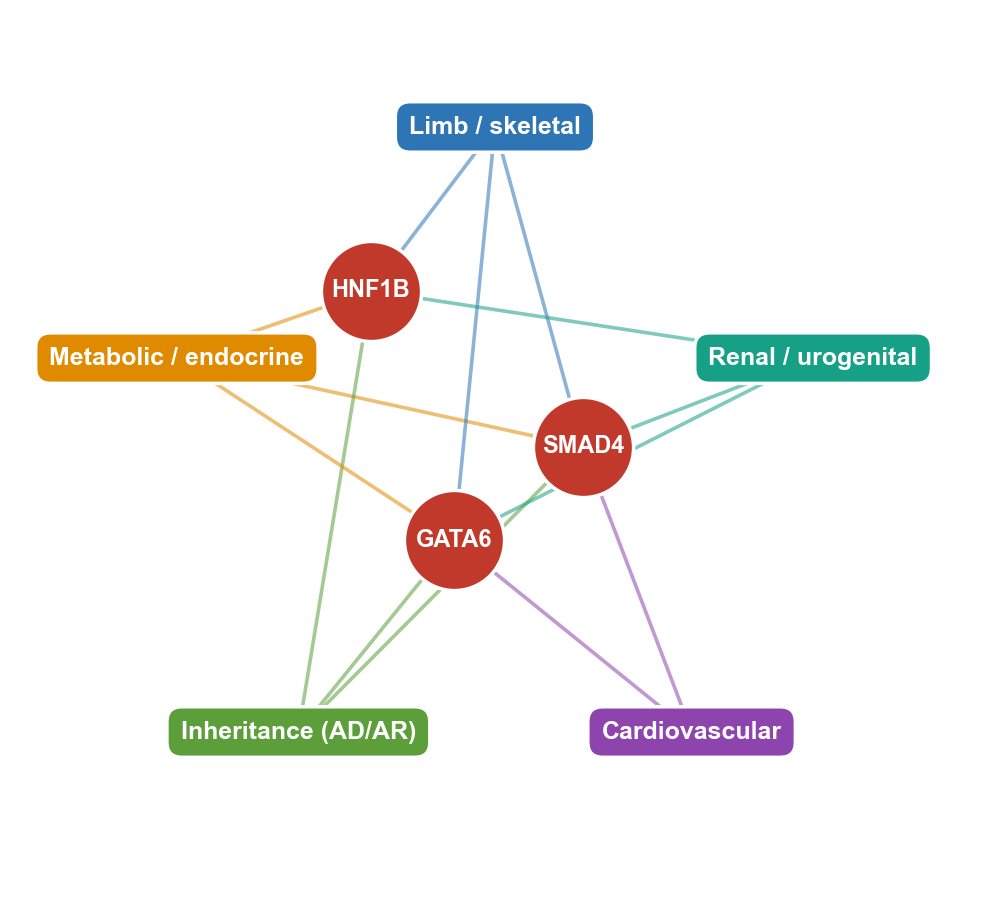

Saved Figure_bridge_TF_network.png / .pdf / .svg


In [3]:
# ============================================================
# Bridge TF network figure (inline, publication-ready)
# ============================================================
%matplotlib inline
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# ---------------- Settings ----------------
GAIN_CSV = "/Volumes/mac1/data/limb/results/HPO_gain_enrichment.csv"
LOSS_CSV = "/Volumes/mac1/data/limb/results/HPO_loss_enrichment.csv"
OUT      = "Figure_bridge_TF_network"   # saved as .png/.pdf/.svg
SHOW_EXTRA_SYSTEMS = True               # False = strict 3 core domains only

gain = pd.read_csv(GAIN_CSV)
loss = pd.read_csv(LOSS_CSV)
all_terms = pd.concat([gain["Term"], loss["Term"]]).dropna().astype(str).unique()

# ---------------- Domain definitions ----------------
# (missing comma after "limb" in the original code is fixed here)
CORE = {
    "Limb / skeletal": [
        "finger", "thumb", "brachydactyly", "clinodactyly", "radial", "ulnar",
        "metacarpal", "syndactyly", "carpal", "limb", "vertebra", "scapula",
        "pelvis", "sacral", "sprengel", "cleido", "osteo", "asymmet", "pes",
        "pectus", "deformity", "malformation", "hypoplasia", "skelet",
    ],
    "Metabolic / endocrine": ["diabetes", "hyperglycemia", "glucose", "insulin", "pancreas"],
    "Inheritance (AD/AR)": ["autosomal dominant inheritance", "autosomal recessive inheritance"],
}
EXTRA = {
    "Cardiovascular": ["cardi", "heart", "aort", "ventric", "septal", "ductus", "arter"],
    "Renal / urogenital": ["kidney", "renal", "uter", "genital", "urinary", "nephr"],
}
COLORS = {
    "Limb / skeletal": "#2E75B6",
    "Metabolic / endocrine": "#E08A00",
    "Inheritance (AD/AR)": "#5B9E3A",
    "Cardiovascular": "#8E44AD",
    "Renal / urogenital": "#16A085",
}

def tfs_for(keywords):
    terms = {t for t in all_terms if any(k in t.lower() for k in keywords)}
    tfs = set()
    for df in (gain, loss):
        sub = df[df["Term"].isin(terms)]
        for genes in sub["Overlap_genes"].dropna():
            tfs.update(g.strip() for g in str(genes).split(";") if g.strip())
    return tfs

core_tfs = {name: tfs_for(kw) for name, kw in CORE.items()}
bridge = set.intersection(*core_tfs.values())
print("Bridge TFs (all 3 core domains):", sorted(bridge))
assert bridge, "No bridge TFs found - check keywords / file paths."

systems = dict(core_tfs)
if SHOW_EXTRA_SYSTEMS:
    for name, kw in EXTRA.items():
        systems[name] = tfs_for(kw)

# ---------------- Graph (bridge TFs <-> systems only) ----------------
G = nx.Graph()
for s, tfs in systems.items():
    for tf in bridge & tfs:
        G.add_edge(tf, s)

sys_nodes = [s for s in systems if s in G]
tf_nodes  = sorted(bridge & set(G.nodes))

n = len(sys_nodes)
pos = {s: (np.cos(2*np.pi*i/n + np.pi/2), np.sin(2*np.pi*i/n + np.pi/2))
       for i, s in enumerate(sys_nodes)}
pos.update(nx.spring_layout(G, pos=pos, fixed=sys_nodes, seed=3, k=0.9, iterations=300))

# ---------------- Draw ----------------
plt.rcParams["font.family"] = ["Arial", "Helvetica", "DejaVu Sans"]
fig, ax = plt.subplots(figsize=(10, 10))
ax.axis("off")

for u, v in G.edges:
    s = u if u in sys_nodes else v
    (x1, y1), (x2, y2) = pos[u], pos[v]
    ax.plot([x1, x2], [y1, y2], color=COLORS[s], lw=2.6, alpha=0.55,
            zorder=1, solid_capstyle="round")

nx.draw_networkx_nodes(G, pos, nodelist=tf_nodes, node_size=5200,
                       node_color="#C0392B", edgecolors="white",
                       linewidths=2.5, ax=ax)
for tf in tf_nodes:
    ax.text(*pos[tf], tf, ha="center", va="center", fontsize=17,
            fontweight="bold", color="white", zorder=5)

for s in sys_nodes:
    ax.text(*pos[s], s, ha="center", va="center", fontsize=18,
            fontweight="bold", color="white", zorder=5,
            bbox=dict(boxstyle="round,pad=0.55,rounding_size=0.6",
                      fc=COLORS[s], ec="white", lw=2.5))

ax.set_xlim(-1.45, 1.45)
ax.set_ylim(-1.35, 1.35)
ax.set_aspect("equal")
plt.tight_layout()

for ext in ("png", "pdf", "svg"):
    fig.savefig(f"{OUT}.{ext}", dpi=600, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved {OUT}.png / .pdf / .svg")

In [45]:
import pandas as pd
import networkx as nx

# ==========================
# Chargement HPO
# ==========================

gain = pd.read_csv("/Volumes/mac1/data/limb/results/HPO_gain_enrichment.csv")
loss = pd.read_csv("/Volumes/mac1/data/limb/results/HPO_loss_enrichment.csv")
hpo = pd.read_csv("/Volumes/mac1/data/limb/HPO.csv")

# ==========================
# Définitions des groupes
# ==========================

#diabetes_terms = {
 #   "Insulin resistance (HP:0000855)",
  #  "Type II diabetes mellitus (HP:0005978)",
  #  "Hyperglycemia (HP:0003074)",
  #  "Maternal diabetes (HP:0009800)",
  #  "Insulin-resistant diabetes mellitus (HP:0000831)"
#}

diabetes_keywords = [
    "diabetes",
    "hyperglycemia",
    "glucose",
    "insulin",
    "pancreas"
]

diabetes_terms = []

for term in hpo["Term"]:


    low = term.lower()

    if any(
        k in low
        for k in diabetes_keywords
    ):
        diabetes_terms.append(term)


inheritance_terms = {
    "Autosomal dominant inheritance (HP:0000006)",
    "Autosomal recessive inheritance (HP:0000007)"
}

limb_keywords = [
    "finger",
    "thumb",
    "brachydactyly",
    "clinodactyly",
    "radial",
    "ulnar",
    "metacarpal",
    "syndactyly",
    "carpal",
    "limb"
    "vertebra",
    "scapula",
    "pelvis",
    "sacral",
    "sprengel",
    "cleido",
    "osteo",
    "asymmet",
    "pes",
    "pectus",
    "deformity",
    "malformation",
    "hypoplasia",
    "skelet"
]

# ==========================
# Fonction extraction TFs
# ==========================

def extract_tfs(df, selected_terms):

    subset = df[df["Term"].isin(selected_terms)]

    tfs = set()

    for genes in subset["Overlap_genes"].dropna():
        tfs.update(
            g.strip()
            for g in genes.split(";")
        )

    return tfs

# ==========================
# TF diabète
# ==========================

diabetes_tfs = extract_tfs(
    loss,
    diabetes_terms
)

diabetes_tfs |= extract_tfs(
    gain,
    diabetes_terms
)

# ==========================
# TF héritabilité
# ==========================

inheritance_tfs = extract_tfs(
    loss,
    inheritance_terms
)

inheritance_tfs |= extract_tfs(
    gain,
    inheritance_terms
)

# ==========================
# TF membre
# ==========================

limb_terms = []

for term in loss["Term"]:

    lower = str(term).lower()

    if any(k in lower for k in limb_keywords):
        limb_terms.append(term)

for term in gain["Term"]:

    lower = str(term).lower()

    if any(k in lower for k in limb_keywords):
        limb_terms.append(term)

limb_tfs = extract_tfs(
    loss,
    set(limb_terms)
)

limb_tfs |= extract_tfs(
    gain,
    set(limb_terms)
)

# ==========================
# Graphe
# ==========================

G = nx.Graph()

G.add_node(
    "Maternal_Diabetes",
    type="phenotype"
)

G.add_node(
    "Congenital_Limb_Defect",
    type="phenotype"
)

G.add_node(
    "Autosomal_Inheritance",
    type="phenotype"
)

for tf in diabetes_tfs:

    G.add_edge(
        "Maternal_Diabetes",
        tf
    )

for tf in limb_tfs:

    G.add_edge(
        "Congenital_Limb_Defect",
        tf
    )

for tf in inheritance_tfs:

    G.add_edge(
        "Autosomal_Inheritance",
        tf
    )

# ==========================
# TFs communs
# ==========================

shared = (
    diabetes_tfs
    & limb_tfs
    & inheritance_tfs
)

print(
    "\nTFs communs diabète + membre + héritabilité\n"
)

for tf in sorted(shared):
    print(tf)

# ==========================
# Export
# ==========================

nx.write_graphml(
    G,
    "TF_diabetes_limb_inheritance.graphml"
)

print(
    "\nGraphML écrit : TF_diabetes_limb_inheritance.graphml"
)


TFs communs diabète + membre + héritabilité

GATA6
HNF1B
SMAD4

GraphML écrit : TF_diabetes_limb_inheritance.graphml


In [46]:
import networkx as nx
import pandas as pd

G = nx.read_graphml(
    "/Volumes/mac1/data/limb/TF_diabetes_limb_inheritance.graphml"
)

degree = nx.degree_centrality(G)

betweenness = nx.betweenness_centrality(
    G,
    normalized=True
)

closeness = nx.closeness_centrality(G)

results = pd.DataFrame(
    {
        "DegreeCentrality": degree,
        "Betweenness": betweenness,
        "Closeness": closeness
    }
)

print(
    results.loc[
        ["GATA6", "HNF1B", "SMAD4"]
    ]
)

results.sort_values(
    "Betweenness",
    ascending=False
).to_csv(
    "centrality_results.csv"
)

       DegreeCentrality  Betweenness  Closeness
GATA6          0.066667     0.010331   0.517241
HNF1B          0.066667     0.010331   0.517241
SMAD4          0.066667     0.010331   0.517241


In [47]:
results.sort_values(
    "Betweenness",
    ascending=False
).head(20)

,DegreeCentrality,Betweenness,Closeness
Autosomal_Inheritance,0.911111,0.786727,0.882353
Congenital_Limb_Defect,0.533333,0.209798,0.529412
Maternal_Diabetes,0.155556,0.011556,0.378151
SMAD4,0.066667,0.010331,0.517241
HNF1B,0.066667,0.010331,0.517241
GATA6,0.066667,0.010331,0.517241
PPARG,0.044444,0.004228,0.483871
HNF1A,0.044444,0.004228,0.483871
HNF4A,0.044444,0.004228,0.483871
PDX1,0.044444,0.004228,0.483871


In [48]:
results.sort_values(
    "DegreeCentrality",
    ascending=False
).head(20)

,DegreeCentrality,Betweenness,Closeness
Autosomal_Inheritance,0.911111,0.786727,0.882353
Congenital_Limb_Defect,0.533333,0.209798,0.529412
Maternal_Diabetes,0.155556,0.011556,0.378151
GATA6,0.066667,0.010331,0.517241
SMAD4,0.066667,0.010331,0.517241
HNF1B,0.066667,0.010331,0.517241
SOX9,0.044444,0.002689,0.505618
TBX19,0.044444,0.002689,0.505618
SOX10,0.044444,0.002689,0.505618
THRB,0.044444,0.002689,0.505618


In [49]:
for node in ["GATA6", "HNF1B", "SMAD4"]:
    print(node)
    print(list(G.neighbors(node)))

GATA6
['Maternal_Diabetes', 'Congenital_Limb_Defect', 'Autosomal_Inheritance']
HNF1B
['Maternal_Diabetes', 'Congenital_Limb_Defect', 'Autosomal_Inheritance']
SMAD4
['Maternal_Diabetes', 'Congenital_Limb_Defect', 'Autosomal_Inheritance']


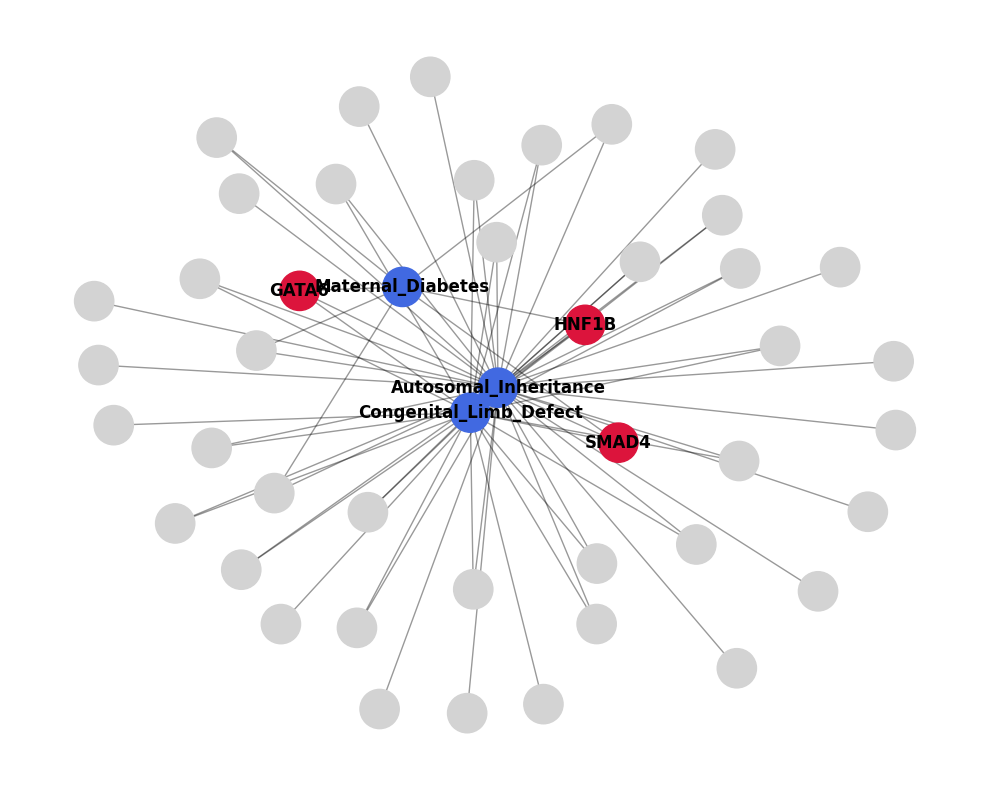

In [50]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.read_graphml(
    "TF_diabetes_limb_inheritance.graphml"
)

plt.figure(figsize=(10,8))

pos = nx.spring_layout(
    G,
    seed=42,
    k=1
)

node_colors = []

for n in G.nodes():

    if n in ["GATA6", "HNF1B", "SMAD4"]:
        node_colors.append("crimson")

    elif n in [
        "Maternal_Diabetes",
        "Congenital_Limb_Defect",
        "Autosomal_Inheritance"
    ]:
        node_colors.append("royalblue")

    else:
        node_colors.append("lightgrey")

nx.draw_networkx_edges(
    G,
    pos,
    alpha=0.4
)

nx.draw_networkx_nodes(
    G,
    pos,
    node_color=node_colors,
    node_size=800
)

labels = {
    n:n for n in
    [
        "GATA6",
        "SMAD4",
        "HNF1B",
        "Maternal_Diabetes",
        "Congenital_Limb_Defect",
        "Autosomal_Inheritance"
    ]
}

nx.draw_networkx_labels(
    G,
    pos,
    labels,
    font_size=12,
    font_weight="bold"
)

plt.axis("off")

plt.tight_layout()

plt.savefig(
    "Bridge_TF_network.png",
    dpi=600,
    bbox_inches="tight"
)

In [51]:
top = results.sort_values(
    "Betweenness",
    ascending=False
).head(15)

/var/folders/b8/sr0nzgbn5c160l4ghjwwhjkr0000gn/T/ipykernel_26786/3805493739.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


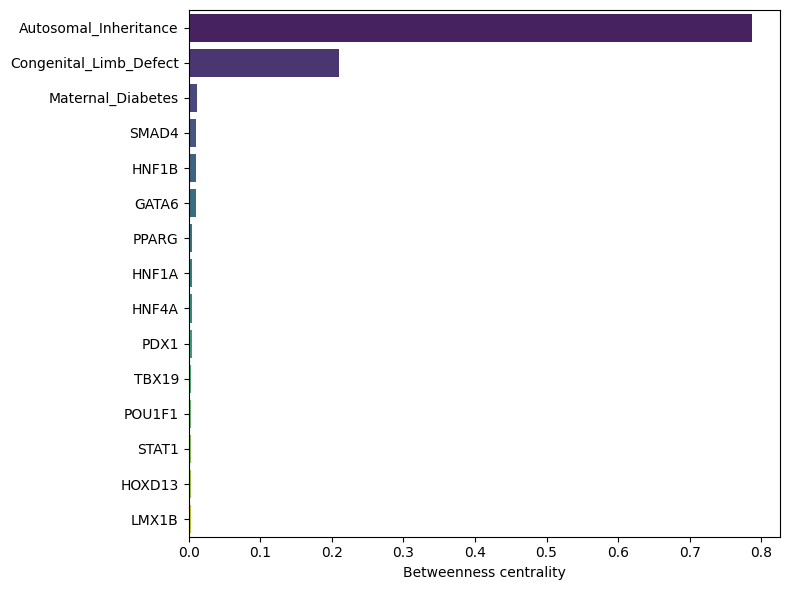

In [52]:
import seaborn as sns

plt.figure(figsize=(8,6))

sns.barplot(
    data=top,
    x="Betweenness",
    y=top.index,
    palette="viridis"
)

plt.xlabel(
    "Betweenness centrality"
)

plt.ylabel("")

plt.tight_layout()


In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
loss = pd.read_csv(
    "/Volumes/mac1/data/limb/results/HPO_loss_enrichment.csv"
)

gain = pd.read_csv(
    "/Volumes/mac1/data/limb/results/HPO_gain_enrichment.csv"
)

print(loss.shape)
print(gain.shape)

(714, 9)
(714, 9)


In [3]:
FDR_THRESHOLD = 0.05

loss_sig = loss[
    loss["FDR"] < FDR_THRESHOLD
]

gain_sig = gain[
    gain["FDR"] < FDR_THRESHOLD
]

print(
    "Loss terms:",
    len(loss_sig)
)

print(
    "Gain terms:",
    len(gain_sig)
)

Loss terms: 133
Gain terms: 55


In [4]:
G = nx.Graph()

def add_hpo_edges(
        df,
        source_type
):

    for _, row in df.iterrows():

        hpo = row["Term"]

        G.add_node(
            hpo,
            node_type="HPO",
            source=source_type
        )

        genes = str(
            row["Overlap_genes"]
        ).split(";")

        genes = [
            g.strip()
            for g in genes
            if g.strip()
        ]

        for tf in genes:

            G.add_node(
                tf,
                node_type="TF"
            )

            G.add_edge(
                tf,
                hpo,
                weight=-1 * (
                    np.log10(
                        row["FDR"]
                    )
                )
            )

add_hpo_edges(
    loss_sig,
    "loss"
)

add_hpo_edges(
    gain_sig,
    "gain"
)

print(
    "Nodes:",
    G.number_of_nodes()
)

print(
    "Edges:",
    G.number_of_edges()
)

Nodes: 221
Edges: 507


In [5]:
degree = nx.degree_centrality(G)

betweenness = nx.betweenness_centrality(
    G,
    normalized=True
)

closeness = nx.closeness_centrality(G)

results = pd.DataFrame(
    {
        "DegreeCentrality":
            degree,
        "Betweenness":
            betweenness,
        "Closeness":
            closeness
    }
)

results.head()

,DegreeCentrality,Betweenness,Closeness
Autosomal recessive inheritance (HP:0000007),0.095455,0.123823,0.382609
FOXI1,0.027273,0.023215,0.309859
GATA6,0.159091,0.108166,0.398551
HOXA2,0.009091,0.001560,0.345912
HOXC13,0.009091,0.001692,0.283505


In [7]:
tf_nodes = [
    n for n,d
    in G.nodes(data=True)
    if d["node_type"]=="TF"
]

tf_results = results.loc[
    tf_nodes
]

tf_results = tf_results.sort_values(
    "Betweenness",
    ascending=False
)

#tf_results.head(30)

In [ ]:
#permuation test
import numpy as np
import pandas as pd
import networkx as nx
from statsmodels.stats.multitest import multipletests

# Bipartite null model: same TF/HPO nodes and same number of edges.
N_NULL_NETWORKS = 10000
FDR_THRESHOLD = 0.05
BETWEENNESS_SOURCES = 100
RANDOM_SEED = 42

tf_nodes = [n for n, data in G.nodes(data=True) if data.get("node_type") == "TF"]
hpo_nodes = [n for n, data in G.nodes(data=True) if data.get("node_type") == "HPO"]
tf_set = set(tf_nodes)
hpo_set = set(hpo_nodes)

if not tf_nodes or not hpo_nodes:
    raise ValueError("G must contain TF and HPO nodes with node_type attributes")

if any(
    not ((u in tf_set and v in hpo_set) or (u in hpo_set and v in tf_set))
    for u, v in G.edges()
 ):
    raise ValueError("G contains edges outside the TF-HPO bipartite structure")

n_possible_edges = len(tf_nodes) * len(hpo_nodes)
n_observed_edges = G.number_of_edges()
if n_observed_edges > n_possible_edges:
    raise ValueError("More observed edges than possible TF-HPO pairs")

rng = np.random.default_rng(RANDOM_SEED)
observed_degree = nx.degree_centrality(G)
observed_betweenness = nx.betweenness_centrality(
    G,
    k=min(BETWEENNESS_SOURCES, G.number_of_nodes()),
    normalized=True,
    seed=RANDOM_SEED
 )

degree_exceedances = np.zeros(len(tf_nodes), dtype=int)
betweenness_exceedances = np.zeros(len(tf_nodes), dtype=int)
n_hpo = len(hpo_nodes)

for _ in range(N_NULL_NETWORKS):
    sampled_edge_ids = rng.choice(
        n_possible_edges,
        size=n_observed_edges,
        replace=False
    )
    randomized_edges = [
        (tf_nodes[edge_id // n_hpo], hpo_nodes[edge_id % n_hpo])
        for edge_id in sampled_edge_ids
    ]

    G_null = nx.Graph()
    G_null.add_nodes_from(G.nodes(data=True))
    G_null.add_edges_from(randomized_edges)

    null_degree = nx.degree_centrality(G_null)
    null_betweenness = nx.betweenness_centrality(
        G_null,
        k=min(BETWEENNESS_SOURCES, G_null.number_of_nodes()),
        normalized=True,
        seed=RANDOM_SEED
    )

    for index, tf in enumerate(tf_nodes):
        degree_exceedances[index] += null_degree[tf] >= observed_degree[tf]
        betweenness_exceedances[index] += (
            null_betweenness[tf] >= observed_betweenness[tf]
        )

degree_p = (degree_exceedances + 1) / (N_NULL_NETWORKS + 1)
betweenness_p = (betweenness_exceedances + 1) / (N_NULL_NETWORKS + 1)

# Correct all TF-by-metric tests together.
all_q = multipletests(
    np.concatenate([degree_p, betweenness_p]),
    method="fdr_bh"
 )[1]

hub_significance = pd.DataFrame(
    {
        "degree_centrality": [observed_degree[tf] for tf in tf_nodes],
        "degree_p": degree_p,
        "degree_q": all_q[:len(tf_nodes)],
        "betweenness": [observed_betweenness[tf] for tf in tf_nodes],
        "betweenness_p": betweenness_p,
        "betweenness_q": all_q[len(tf_nodes):]
    },
    index=tf_nodes
 )

hub_significance["significant_degree"] = (
    hub_significance["degree_q"] < FDR_THRESHOLD
 )
hub_significance["significant_betweenness"] = (
    hub_significance["betweenness_q"] < FDR_THRESHOLD
 )
hub_significance["significant_hub"] = (
    hub_significance["significant_degree"]
    | hub_significance["significant_betweenness"]
 )

hub_significance = hub_significance.sort_values(
    ["significant_hub", "betweenness_q", "degree_q"],
    ascending=[False, True, True]
 )
hub_significance.to_csv("TF_hub_permutation_test.csv", index_label="TF")

print(
    f"Significant TF hubs (FDR < {FDR_THRESHOLD}): "
    f"{hub_significance['significant_hub'].sum()} / {len(tf_nodes)}"
 )
display(hub_significance[hub_significance["significant_hub"]])
print("Saved: TF_hub_permutation_test.csv")

Significant TF hubs (FDR < 0.05): 7 / 49


,degree_centrality,degree_p,degree_q,betweenness,betweenness_p,betweenness_q,significant_degree,significant_betweenness,significant_hub
GATA6,0.159091,0.0001,0.001225,0.115231,0.000100,0.001225,True,True,True
TBX1,0.222727,0.0001,0.001225,0.206522,0.000100,0.001225,True,True,True
HOXD13,0.222727,0.0001,0.001225,0.189502,0.000100,0.001225,True,True,True
HNF1B,0.118182,0.0001,0.001225,0.108981,0.000300,0.002940,True,True,True
SMAD4,0.100000,0.0004,0.003563,0.088282,0.002100,0.017148,True,True,True
HOXA13,0.122727,0.0001,0.001225,0.067673,0.024598,0.150660,True,False,True
NFIX,0.109091,0.0002,0.002178,0.060919,0.040896,0.226466,True,False,True


Saved: TF_hub_permutation_test.csv


In [8]:
tf_results.loc[
    [
        "GATA6",
        "HNF1B",
        "SMAD4"
    ]
]

,DegreeCentrality,Betweenness,Closeness
GATA6,0.159091,0.108166,0.398551
HNF1B,0.118182,0.093394,0.369128
SMAD4,0.100000,0.075995,0.366667


In [10]:
top_hubs = (
    tf_results
    .sort_values(
        "Betweenness",
        ascending=False
    )
    .head(20)
)

#top_hubs

In [16]:
top_hubs.index

Index(['TBX1', 'HOXD13', 'GATA6', 'HNF1B', 'SMAD4', 'NFIX', 'HOXA13', 'TBX2',
       'POU1F1', 'FOXG1', 'LMX1B', 'THRB', 'HMGA2', 'PDX1', 'SOX9', 'FOXC1',
       'PPARG', 'HNF1A', 'PAX6', 'IRX5'],
      dtype='object')

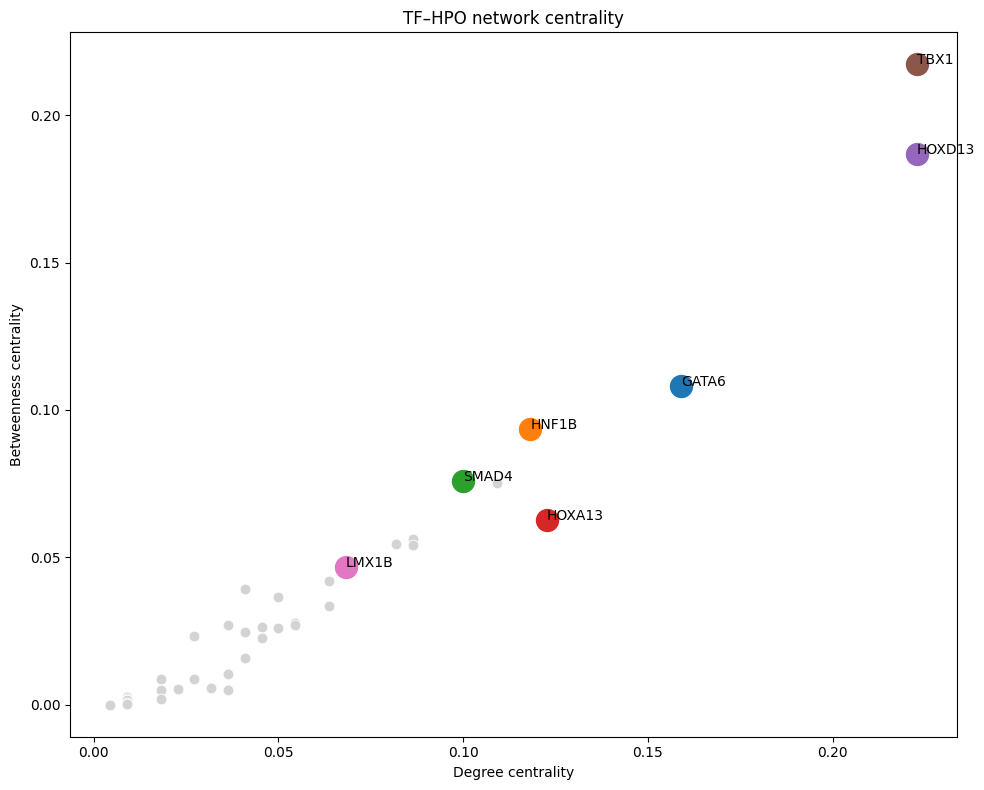

In [ ]:
import seaborn as sns

plt.figure(
    figsize=(10,8)
)

sns.scatterplot(

    data=tf_results,

    x="DegreeCentrality",

    y="Betweenness",

    color="lightgrey",

    s=60
)

for gene in [
    "GATA6",
    "HNF1B",
    "SMAD4",
    "HOXA13",
    "HOXD13",
    "TBX1",
    "LMX1B"
]:

    if gene in tf_results.index:

        plt.scatter(
            tf_results.loc[
                gene,
                "DegreeCentrality"
            ],

            tf_results.loc[
                gene,
                "Betweenness"
            ],

            s=250
        )

        plt.text(

            tf_results.loc[
                gene,
                "DegreeCentrality"
            ],

            tf_results.loc[
                gene,
                "Betweenness"
            ],

            gene,

            fontsize=10
        )

plt.xlabel(
    "Degree centrality"
)

plt.ylabel(
    "Betweenness centrality"
)

plt.title(
    "TF–HPO network centrality"
)

plt.tight_layout()

plt.savefig(
    "/Volumes/mac1/data/limb/text/submit/TF_HPO_centrality.tiff",
    dpi=600,
    format="tiff"
)

plt.show()

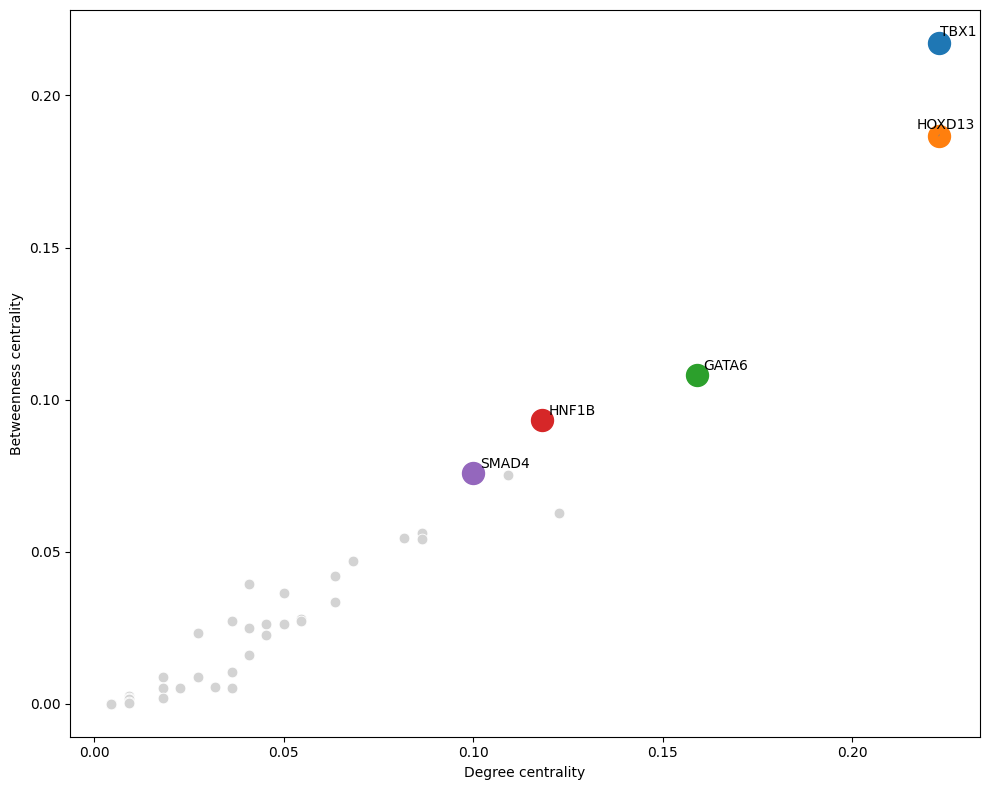

In [12]:
import seaborn as sns
from adjustText import adjust_text

plt.figure(
    figsize=(10,8)
)

sns.scatterplot(

    data=tf_results,

    x="DegreeCentrality",

    y="Betweenness",

    color="lightgrey",

    s=60
)

texts = []

for gene in top_hubs.index[:5]:
    if gene in tf_results.index:   
            x = tf_results.loc[gene, "DegreeCentrality"]
            y = tf_results.loc[gene, "Betweenness"]

            plt.scatter(x, y, s=250)
            texts.append(plt.text(x, y, gene, fontsize=10))

adjust_text(
    texts,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.5)
)

plt.xlabel(
    "Degree centrality"
)

plt.ylabel(
    "Betweenness centrality"
)

#plt.title("TF–HPO network centrality")

plt.tight_layout()

plt.savefig(
    "/Volumes/mac1/data/limb/text/submit/TF_HPO_centrality.tiff",
    dpi=600,
    format="tiff"
)

plt.show()

In [62]:
nx.write_graphml(
    G,
    "TF_HPO_network.graphml"
)

print(
    "Saved: TF_HPO_network.graphml"
)

Saved: TF_HPO_network.graphml


In [63]:
top_bridge = (
    tf_results
    .sort_values(
        [
            "Betweenness",
            "DegreeCentrality"
        ],
        ascending=False
    )
)

top_bridge.head(20)

,DegreeCentrality,Betweenness,Closeness
TBX1,0.222727,0.217234,0.421456
HOXD13,0.222727,0.186659,0.405904
GATA6,0.159091,0.108166,0.398551
HNF1B,0.118182,0.093394,0.369128
SMAD4,0.100000,0.075995,0.366667
NFIX,0.109091,0.075341,0.369128
HOXA13,0.122727,0.062737,0.369128
TBX2,0.086364,0.056177,0.335366
POU1F1,0.081818,0.054471,0.375427
FOXG1,0.086364,0.054251,0.340557


In [27]:
import pandas as pd

gain = pd.read_csv("/Volumes/mac1/data/limb/results/HPO_gain_enrichment.csv")
loss = pd.read_csv("/Volumes/mac1/data/limb/results/HPO_loss_enrichment.csv")

hpo_all = pd.concat([gain, loss])

def get_tf_phenotypes(tf):

    tf = tf.upper()

    selected = []

    for _, row in hpo_all.iterrows():

        genes = str(
            row["Overlap_genes"]
        ).split(";")

        genes = [
            x.strip().upper()
            for x in genes
        ]

        if tf in genes:

            selected.append({
                "HPO": row["Term"],
                "FDR": row["FDR"],
                "OR": row["OddsRatio"]
            })

    return pd.DataFrame(selected).sort_values(
        "FDR"
    )

gata6 = get_tf_phenotypes("GATA6")
hnf1b = get_tf_phenotypes("HNF1B")
smad4 = get_tf_phenotypes("SMAD4")

gata6["TF"] = 'GATA6'
hnf1b["TF"] = "HNF1B"
smad4["TF"] = "SMAD4"

gata6.head(20)

,HPO,FDR,OR,TF
0,Autosomal recessive inheritance (HP:0000007),1.397702e-13,50.782609,GATA6
1,Autosomal dominant inheritance (HP:0000006),6.440101e-10,17.848252,GATA6
2,Clinodactyly of the 5th finger (HP:0004209),2.698574e-04,35.554054,GATA6
3,Radial deviation of finger (HP:0009466),5.366201e-04,26.655405,GATA6
4,Brachydactyly syndrome (HP:0001156),4.377557e-03,70.213333,GATA6
5,Patent ductus arteriosus (HP:0001643),4.529345e-03,22.063758,GATA6
13,Tetralogy of Fallot (HP:0001636),5.625017e-03,inf,GATA6
12,Abnormal connection of the cardiac segments (H...,5.625017e-03,inf,GATA6
10,Transposition of the great arteries (HP:0001669),5.625017e-03,inf,GATA6
11,Abnormal ventriculo-arterial connection (HP:00...,5.625017e-03,inf,GATA6


In [28]:
bridge_tf = pd.concat([gata6, smad4, hnf1b])
bridge_tf["HPO_id"] = bridge_tf.HPO.apply(lambda x: x.split("(")[1].replace(")", "").strip())
bridge_tf["HPO_term"] = bridge_tf.HPO.apply(lambda x: x.split("(")[0].strip())
bridge_tf.head()

,HPO,FDR,OR,TF,HPO_id,HPO_term
0,Autosomal recessive inheritance (HP:0000007),1.397702e-13,50.782609,GATA6,HP:0000007,Autosomal recessive inheritance
1,Autosomal dominant inheritance (HP:0000006),6.440101e-10,17.848252,GATA6,HP:0000006,Autosomal dominant inheritance
2,Clinodactyly of the 5th finger (HP:0004209),2.698574e-04,35.554054,GATA6,HP:0004209,Clinodactyly of the 5th finger
3,Radial deviation of finger (HP:0009466),5.366201e-04,26.655405,GATA6,HP:0009466,Radial deviation of finger
4,Brachydactyly syndrome (HP:0001156),4.377557e-03,70.213333,GATA6,HP:0001156,Brachydactyly syndrome


In [71]:
bridge_tf.to_csv('/Volumes/mac1/data/limb/results/bridge_tf.csv')

In [47]:
gata6_terms = set(
    gata6["HPO"]
)

hnf1b_terms = set(
    hnf1b["HPO"]
)

smad4_terms = set(
    smad4["HPO"]
)

common = (
    gata6_terms
    &
    hnf1b_terms
    &
    smad4_terms
)

print(
    "Phenotypes shared by all three TFs:"
)

for hpo in sorted(common):
    print(hpo)

Phenotypes shared by all three TFs:
Autosomal dominant inheritance (HP:0000006)
Cryptorchidism (HP:0000028)


In [48]:
gata6_only = (
    gata6_terms
    - hnf1b_terms
    - smad4_terms
)

sorted(gata6_only)

['Abnormal biliary tract morphology (HP:0012440)',
 'Abnormal connection of the cardiac segments (HP:0011545)',
 'Abnormal umbilical cord blood vessels (HP:0011403)',
 'Abnormal ventriculo-arterial connection (HP:0011563)',
 'Abnormalities of placenta or umbilical cord (HP:0001194)',
 'Abnormality of the aortic arch (HP:0012303)',
 'Abnormality of the fetal cardiovascular system (HP:0010948)',
 'Abnormality of the umbilical cord (HP:0010881)',
 'Autosomal recessive inheritance (HP:0000007)',
 'Broad forehead (HP:0000337)',
 'Clinodactyly of the 5th finger (HP:0004209)',
 'Congenital diaphragmatic hernia (HP:0000776)',
 'Congenital malformation of the right heart (HP:0011723)',
 'Dolichocephaly (HP:0000268)',
 'Double outlet right ventricle (HP:0001719)',
 'Hyperglycemia (HP:0003074)',
 'Inguinal hernia (HP:0000023)',
 'Intestinal malrotation (HP:0002566)',
 'Patent foramen ovale (HP:0001655)',
 'Periauricular skin pits (HP:0100277)',
 'Preauricular pit (HP:0004467)',
 'Pulmonic stenosi

In [49]:
hnf1b_only = (
    hnf1b_terms
    - gata6_terms
    - smad4_terms

)
sorted(hnf1b_only)

['Abnormal enzyme/coenzyme activity (HP:0012379)',
 'Abnormal glucose tolerance (HP:0001952)',
 'Abnormality of alkaline phosphatase activity (HP:0004379)',
 'Abnormality of male internal genitalia (HP:0000022)',
 'Abnormality of nucleobase metabolism (HP:0010932)',
 'Abnormality of purine metabolism (HP:0004352)',
 'Aplasia/hypoplasia of the uterus (HP:0008684)',
 'Bicornuate uterus (HP:0000813)',
 'Cerebral cortical atrophy (HP:0002120)',
 'Elevated hepatic transaminases (HP:0002910)',
 'Exocrine pancreatic insufficiency (HP:0001738)',
 'Glucose intolerance (HP:0000833)',
 'Gout (HP:0001997)',
 'Hyperuricemia (HP:0002149)',
 'Hypoplasia of the uterus (HP:0000013)',
 'Hypospadias (HP:0000047)',
 'Hypothyroidism (HP:0000821)',
 'Increased purine levels (HP:0004368)',
 'Insulin resistance (HP:0000855)',
 'Late onset (HP:0003584)',
 'Low posterior hairline (HP:0002162)',
 'Multicystic kidney dysplasia (HP:0000003)',
 'Nephropathy (HP:0000112)',
 'Oligohydramnios (HP:0001562)',
 'Proteinu

In [50]:
smad4_only = (
    smad4_terms
    - gata6_terms
    - hnf1b_terms
)
sorted(smad4_only)

['2-3 toe syndactyly (HP:0004691)',
 'Abdominal pain (HP:0002027)',
 'Abnormal albumin level (HP:0012116)',
 'Abnormality of potassium homeostasis (HP:0011042)',
 'Abnormality of the hepatic vasculature (HP:0006707)',
 'Abnormality of the pericardium (HP:0001697)',
 'Abnormality of the vasculature of the conjunctiva (HP:0008054)',
 'Abnormality of the wing of the ilium (HP:0011867)',
 'Aortic valve stenosis (HP:0001650)',
 'Arteriovenous malformation (HP:0100026)',
 'Blepharophimosis (HP:0000581)',
 'Broad ribs (HP:0000885)',
 'Cavernous hemangioma (HP:0001048)',
 'Cerebral ischemia (HP:0002637)',
 'Coarctation of aorta (HP:0001680)',
 'Colon cancer (HP:0003003)',
 'Congestive heart failure (HP:0001635)',
 'Conjunctival telangiectasia (HP:0000524)',
 'Cranial hyperostosis (HP:0004437)',
 'Craniofacial hyperostosis (HP:0004493)',
 'Deeply set eye (HP:0000490)',
 'Epistaxis (HP:0000421)',
 'Esophageal varix (HP:0002040)',
 'Fine hair (HP:0002213)',
 'Gastrointestinal carcinoma (HP:000267

In [29]:
categories = {

    "Limb_Skeletal": [
        "finger","thumb","brachydactyly","clinodactyly",
        "syndactyly","toe","vertebral","spond","ilium",
        "skelet","rib","pelvis","scapula","sprengel",
        "fusion","malformation","deformity","spond"
    ],

    "Respiratory": [
        "trachea","respir"
    ],

    "Cardiac": [
        "cardiac","ventricular","aortic","tetralogy",
        "arteriosus","pulmonic","foramen",
        "heart","coarctation","mitral",
        "pericardium","transposition"
    ],

    "Metabolic": [
        "diabetes","glucose","insulin","homostasis","potas","albumin",
        "hyperglycemia","pancreas",
        "purine","gout","thyroid","pubert"
    ],

    "Renal_Urogenital": [
        "renal","kidney","ureter",
        "nephro","proteinuria",
        "hypospadias","uterus",
        "oligohydramnios"
    ],

    "Craniofacial": [
        "hypertelorism","nasal",
        "philtrum","ear","microtia",
        "ptosis","blepharo","lip",
        "malar","maxilla","mouth",
        "eyebrow","forehead"
    ],

    "Vascular": [
        "hemangioma","telang",
        "vascular","embol",
        "hematoma","varix",
        "thromb"
    ],

    "Gastrointestinal": [
        "intestinal","colon",
        "gastro","esophageal",
        "rectal","malrotation",
        "polyp","polyposis"
    ],

    "Hepatobiliary": [
        "biliary","hepatic",
        "portal"
    ],

    "Developmental_Growth": [
        "late onset",
        "congenital",
        "hypoplasia",
        "agenesis"
    ],

    "Tumoral": [
        "cancer","carcinom","tumor","malignant","angiom","telangectasia"
    ]
}

In [30]:
tf_dict = {
    "GATA6": gata6_only,
    "HNF1B": hnf1b_only,
    "SMAD4": smad4_only,
}

import pandas as pd

heatmap_data = []

for tf, phenotypes in tf_dict.items():

    row = {"TF": tf}

    for cat, keywords in categories.items():

        count = 0

        for pheno in phenotypes:

            p = pheno.lower()

            if any(
                kw.lower() in p
                for kw in keywords
            ):
                count += 1

        row[cat] = count

    heatmap_data.append(row)

heatmap_df = pd.DataFrame(
    heatmap_data
).set_index("TF")

heatmap_df


NameError: name 'gata6_only' is not defined

In [53]:
h_pc = heatmap_df.map

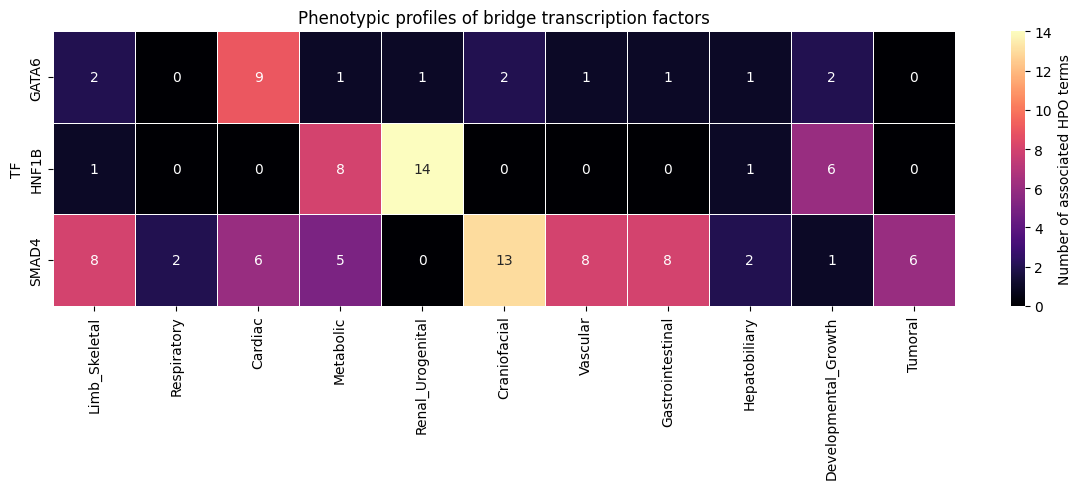

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(
    figsize=(12,5)
)

sns.heatmap(

    heatmap_df,

    annot=True,

    cmap="magma",

    linewidths=.5,

    cbar_kws={
        "label":
        "Number of associated HPO terms"
    }
)

plt.title(
    "Phenotypic profiles of bridge transcription factors"
)

plt.tight_layout()

plt.savefig(
    "Bridge_TF_heatmap.png",
    dpi=600
)

plt.show()


In [55]:
tf_results.to_csv('/Volumes/mac1/data/limb/results/TF_centrality_results.csv')

NameError: name 'tf_results' is not defined

In [32]:
import re
from collections import defaultdict, Counter

import pandas as pd
import numpy as np
import networkx as nx

import seaborn as sns
import matplotlib.pyplot as plt


# =====================================================
# 1. PARSE HPO OBO
# =====================================================

def parse_hpo_obo(obo_file):

    terms = {}

    current = None

    with open("/Volumes/mac1/data/limb/hp.obo", "r") as fh:

        for line in fh:

            line = line.strip()

            if line == "[Term]":

                if current:
                    terms[current["id"]] = current

                current = {
                    "id": None,
                    "name": None,
                    "parents": []
                }

                continue

            if current is None:
                continue

            if line.startswith("id:"):

                current["id"] = line.replace(
                    "id:",
                    ""
                ).strip()

            elif line.startswith("name:"):

                current["name"] = line.replace(
                    "name:",
                    ""
                ).strip()

            elif line.startswith("is_a:"):

                parent = (
                    line.replace(
                        "is_a:",
                        ""
                    )
                    .split("!")[0]
                    .strip()
                )

                current["parents"].append(
                    parent
                )

    if current:
        terms[current["id"]] = current

    return terms


terms = parse_hpo_obo(
    "hp.obo"
)

print(
    "HPO terms:",
    len(terms)
)

HPO terms: 20482


In [33]:
G_hpo = nx.DiGraph()

for hpo_id, term in terms.items():

    G_hpo.add_node(
        hpo_id,
        name=term["name"]
    )

    for parent in term["parents"]:

        G_hpo.add_edge(
            hpo_id,
            parent
        )

print(
    "Nodes:",
    G_hpo.number_of_nodes()
)

Nodes: 20527


In [34]:
print("Nodes:", G_hpo.number_of_nodes())
print("Edges:", G_hpo.number_of_edges())

roots = [
    n for n in G_hpo.nodes()
    if G_hpo.out_degree(n) == 0
]

print("Root terms:", len(roots))

Nodes: 20527
Edges: 24436
Root terms: 634


In [35]:
import pandas as pd
import networkx as nx
from collections import deque

# =====================================================
# SYSTEM DEFINITIONS
# =====================================================

SYSTEM_KEYWORDS = {
    "Metabolism/homeostasis": [
            "nephrotic",
            "proteinuri",
            "hematuria",
            "metabolism",
            "metabolic",
            "homeostasis",
            "albumin",
            "glucose",
            "glycosuria",
            "glucose intolerance",
            "abnormal glucose tolerance",
            "potassium",
            "hypokalemia",
            "hyperkalemia",
            "hyperuricemia",
            "purine",
            "nucleobase",
            "alkaline phosphatase",
            "enzyme",
            "coenzyme",
            "endocrine",
            "diabetes",
            "diabetic",
            "insulin",
            "thyroid",
            "hypothyroidism",
            "hyperthyroidism",
            "hyperglycemia",
            "hypoglycemia",
            "puberty",
            "precocious puberty",
            "growth",
            "trophy"
        ],

     "Neoplastic process": [
            "cancer","carcinom","tumor","malignant","angiom","telangectasia"
        ],

    "Genitourinary system": [
        "renal", "kidney", "nephro", "neph",
        "ureter", "ureteral", "urinary",
        "urine", "bladder",
        "nephrolithiasis",
        "nephropathy",
        "proteinuria",
        "hematuria",
        "renal agenesis",
        "renal hypoplasia",
        "renal dysplasia",
        "chronic kidney disease",
        "cryptorchid",
        "hypospadias",
        "genital",
        "scrotum",
        "testis",
        "testicular",
        "male internal genitalia",
        "uterus",
        "uterine",
        "bicornuate uterus",
        "ovary",
        "ovarian",
        "glomerulo",
        "hematuri",
        "nephr"
    ],

    "Cardiovascular system": [
        "heart",
        "cardiac",
        "cardiovascular",
        "ventricular",
        "atrioventricular",
        "atrial",
        "septal defect",
        "tetralogy",
        "aorta",
        "aortic",
        "coarctation",
        "arteriosus",
        "artery",
        "arterial",
        "valve",
        "valvular",
        "vascul",
        "vasculature",
        "pericard",
        "pulmonary hypertension",
        "truncus arteriosus",
        "double outlet right ventricle",
        "transposition of the great arteries",
        "patent foramen ovale",
        "patent ductus arteriosus",
        "mitral",
        "congestive heart failure"
    ],

    "Respiratory system": [
        "respiratory",
        "lung",
        "pulmonary",
        "trachea",
        "tracheal",
        "airway",
        "hemoptysis",
        "respiratory failure"
    ],

    "Digestive system": [
        "digestive",
        "gastro",
        "gastrointestinal",
        "intestinal",
        "intestine",
        "colon",
        "colonic",
        "rectal",
        "rectum",
        "bowel",
        "esophageal",
        "esophagus",
        "pyloric",
        "stomach",
        "gastric",
        "hepatic",
        "liver",
        "biliary",
        "pancreas",
        "pancreatic",
        "malrotation",
        "polyp",
        "polyposis",
        "colon cancer",
        "gastrointestinal carcinoma",
        "intestinal carcinoma",
        "abdominal pain",
        "portal hypertension",
        "esophageal varix"
    ],


    "Nervous system": [
        "brain",
        "cerebral",
        "cortical",
        "autism",
        "stroke",
        "migraine",
        "neurolog",
        "seizure",
        "epilepsy",
        "ischemia"
    ],

    "Skeletal system": [
        "skeletal",
        "bone",
        "vertebral",
        "vertebra",
        "rib",
        "ilium",
        "ilia",
        "iliac",
        "maxilla",
        "mandibular",
        "mandible",
        "cranial",
        "calvaria",
        "hyperostosis",
        "brachydactyly",
        "clinodactyly",
        "syndactyly",
        "finger",
        "toe",
        "platyspondyly",
        "sprengel",
        "radial",
        "arm",
        "phalang",
        "muscul",
        "patella",
        "valgus",
        "cubit",
        "varus",
        "exostose",
        "elbow",
        "lumbar",
        "lordosis",
        "osteoarthritis",
        "pectus",
        "pes",
        "pterygium",
        "rib",
        "talipes"
    ],

    "Eye": [
        "eye",
        "ocular",
        "retina",
        "retinal",
        "conjunctiva",
        "ptosis",
        "blepharo",
        "hypermetropia",
        "hypertelorism",
        "kerato",
        "cornea",
        "ptosis"
    ],

    "Ear": [
        "ear",
        "auricular",
        "preauricular",
        "periauricular",
        "microtia"
    ],

    "Blood": [
        "blood",
        "anemia",
        "hematoma",
        "hematochezia",
        "hemat",
        "hemoglobin",
        "thrombo",
        "epistaxis"
    ],

    "Immune system": [
        "immune",
        "immun"
    ],

    "Integument": [
        "skin",
        "hair",
        "eyebrow",
        "nail",
        "telangiectasia",
        "onych"
    ],

    "Growth": [
        "growth",
        "growth retardation",
        "intrauterine growth",
        "short stature"
    ],

    "Head and neck": [
        "forehead",
        "craniofacial",
        "facial",
        "midface",
        "nasal",
        "nose",
        "philtrum",
        "lip",
        "mouth",
        "neck"
    ],

    "Connective tissue": [
        "hernia",
        "connective tissue",
        "diaphragmatic hernia"
    ]
}

# =====================================================
# TEXT CLASSIFICATION
# =====================================================

def classify_from_text(text):

    text = str(text).lower()

    # exact matches first
    for system, keywords in SYSTEM_KEYWORDS.items():
        for kw in keywords:
            if kw == text:
                return system

    # substring matches
    for system, keywords in SYSTEM_KEYWORDS.items():
        for kw in keywords:
            if kw in text:
                return system

    return None


# =====================================================
# HPO SYSTEM INFERENCE
# =====================================================

def classify_hpo_system(hpo_id, hpo_term, G):

    # Step 1: direct term match
    system = classify_from_text(hpo_term)

    if system is not None:
        return system

    # Step 2: search ancestors

    if hpo_id not in G:
        return "Unclassified"

    visited = set()
    queue = deque([hpo_id])

    while queue:

        node = queue.popleft()

        if node in visited:
            continue

        visited.add(node)

        node_name = str(
            G.nodes[node].get("name", "")
        )

        system = classify_from_text(node_name)

        if system is not None:
            return system

        # child -> parent graph
        for parent in G.successors(node):
            queue.append(parent)

    return "Unclassified"


# =====================================================
# APPLY TO DATAFRAME
# =====================================================
bridge_tf = pd.read_csv('/Volumes/mac1/data/limb/results/bridge_tf.csv')
bridge_tf["System"] = bridge_tf.apply(
    lambda row: classify_hpo_system(
        row["HPO_id"],
        row["HPO_term"],
        G_hpo
    ),
    axis=1
)

# =====================================================
# CHECK UNCLASSIFIED TERMS
# =====================================================

unclassified = bridge_tf[bridge_tf["System"] == "Unclassified"]

print(f"Unclassified terms: {len(unclassified)}")

if len(unclassified) > 0:
    print(
        unclassified[
            ["HPO_id", "HPO_term"]
        ].sort_values("HPO_term")
    )

# =====================================================
# EXPORT
# =====================================================

bridge_tf[["TF","HPO_id","HPO_term","System"]].to_csv(
    "/Volumes/mac1/data/limb/results/OntoSystemBridgeTf_corrected.csv",
    index=False
)

print(
    "Saved: OntoSystemBridgeTf_corrected.csv"
)

Unclassified terms: 9
         HPO_id                                     HPO_term
19   HP:0001194  Abnormalities of placenta or umbilical cord
31   HP:0010881            Abnormality of the umbilical cord
1    HP:0000006               Autosomal dominant inheritance
41   HP:0000006               Autosomal dominant inheritance
126  HP:0000006               Autosomal dominant inheritance
0    HP:0000007              Autosomal recessive inheritance
69   HP:0010566                                    Hamartoma
164  HP:0003584                                   Late onset
150  HP:0001562                              Oligohydramnios
Saved: OntoSystemBridgeTf_corrected.csv


System  Cardiovascular system  Genitourinary system  Digestive system  \
TF                                                                      
GATA6                      14                     4                 3   
HNF1B                       0                    17                 4   
SMAD4                      10                     2                11   

System  Metabolism/homeostasis  Neoplastic process  Skeletal system  \
TF                                                                    
GATA6                        4                   0                4   
HNF1B                       14                   0                3   
SMAD4                        7                   4               17   

System  Nervous system  Respiratory system  Blood  Head and neck  Eye  Ear  \
TF                                                                           
GATA6                0                   0      1              2    0    2   
HNF1B                1                   0  

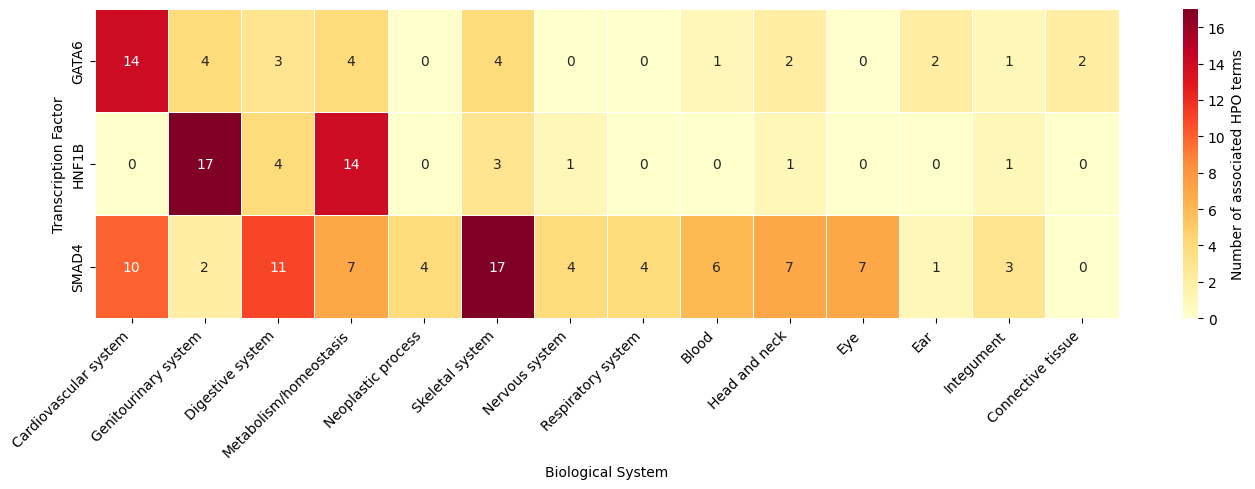

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ==========================================
# LOAD DATA
# ==========================================

df = pd.read_csv("/Volumes/mac1/data/limb/results/OntoSystemBridgeTf_corrected.csv")

# enlever les non classés
df = df[df["System"] != "Unclassified"]

# ==========================================
# COUNT HPO TERMS PER TF/SYSTEM
# ==========================================

heatmap_df = (
    df.groupby(["TF", "System"])
      .size()
      .unstack(fill_value=0)
)

# ordre biologique des colonnes

system_order = [
    "Cardiovascular system","Genitourinary system",
    "Digestive system",
    "Metabolism/homeostasis",
    "Neoplastic process",
    "Skeletal system",
    "Nervous system",
    "Respiratory system",
    "Blood",
    "Head and neck",
    "Eye",
    "Ear",
    "Integument",
    "Connective tissue",
    "Growth"
]

cols = [c for c in system_order if c in heatmap_df.columns]

heatmap_df = heatmap_df[cols]

print(heatmap_df)
# ==========================================
# PLOT
# ==========================================

plt.figure(figsize=(14, 5))

sns.heatmap(
    heatmap_df,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={
        "label": "Number of associated HPO terms"
    }
)

#plt.title(
 #   "Distribution of HPO Systems Across TFs",
  #  fontsize=14,
    # weight="bold"
#)

plt.xlabel("Biological System")
plt.ylabel("Transcription Factor")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "/Volumes/mac1/data/limb/text/submit/TF_System_Heatmap.tiff",
    dpi=600,
    format="tiff",
    bbox_inches="tight"
)

plt.show()

In [74]:
import pandas as pd

# Charger les résultats HPO
df = pd.read_csv("/Volumes/mac1/data/limb/results/OntoSystemBridgeTf_corrected.csv")

# Bridge TFs
bridge_tfs = ["GATA6", "HNF1B", "SMAD4"]

# Conserver uniquement ces TFs
df = df[df["TF"].isin(bridge_tfs)]

# Définition des catégories
metabolic_systems = [
    "Metabolism/homeostasis",
]

skeletal_systems = [
    "Skeletal system"
]

neoplasm = ["Neoplastic process"]
rows = []

for tf in bridge_tfs:

    sub = df[df["TF"] == tf]

    metabolic_terms = sorted(
        sub[
            sub["System"].isin(metabolic_systems)
        ]["HPO_term"].dropna().unique()
    )

    skeletal_terms = sorted(
        sub[
            sub["System"].isin(skeletal_systems)
        ]["HPO_term"].dropna().unique()
    )

    neoplasm_terms = sorted(
        sub[
            sub["System"].isin(neoplasm)
        ]["HPO_term"].dropna().unique()
    )
    
    rows.append({
        "TF": tf,
        "Metabolic_phenotypes": "; ".join(metabolic_terms),
        "Neoplastic_phenotypes": "; ".join(neoplasm_terms),
        "Skeletal_phenotypes": "; ".join(skeletal_terms),
        "N_metabolic": len(metabolic_terms),
        "N_skeletal": len(skeletal_terms),
        "N_neoplasm": len(neoplasm_terms)

    })

summary_df = pd.DataFrame(rows)

print(summary_df)

summary_df.to_csv(
    "BridgeTF_metabolic_skeletal_summary.csv",
    index=False
)

      TF                               Metabolic_phenotypes  \
0  GATA6  Abnormality of urine glucose concentration; Gl...   
1  HNF1B  Abnormal enzyme/coenzyme activity; Abnormal gl...   
2  SMAD4  Abnormal albumin level; Abnormality of potassi...   

                               Neoplastic_phenotypes  \
0                                                      
1                                                      
2  Cavernous hemangioma; Hemangiomatosis; Maligna...   

                                 Skeletal_phenotypes  N_metabolic  N_skeletal  \
0  Brachydactyly syndrome; Clinodactyly of the 5t...            4           4   
1      Gout; Mandibular prognathia; Sprengel anomaly           14           3   
2  2-3 toe syndactyly; Abnormality of the wing of...            7          17   

   N_neoplasm  
0           0  
1           0  
2           4  


In [19]:
! pip install pillow


In [20]:
from PIL import Image

img = Image.open("/Volumes/mac1/data/limb/text/submit/Fig 2.png").convert("RGB")

img.save(
    "/Volumes/mac1/data/limb/text/submit/Fig 2.tiff",
    format="TIFF",
    dpi=(600, 600),
    compression="tiff_lzw"
)

In [22]:
from PIL import Image, ImageFilter

img = Image.open("/Volumes/mac1/data/limb/text/submit/Fig 2.tiff")

sharpened = img.filter(
    ImageFilter.UnsharpMask(
        radius=2,      # edge width
        percent=150,   # sharpening strength
        threshold=3    # ignore minor variations/noise
    )
)

sharpened.save(
    "/Volumes/mac1/data/limb/text/submit/image_sharp.tiff",
    dpi=(600, 600),
    compression="tiff_lzw"
)
